In [2]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)


In [5]:
X = df.drop("Churn", axis=1)

In [6]:
y = df["Churn"]

In [7]:
print("Features Shape:", X.shape)
print("Target Shape:", y.shape)


Features Shape: (7043, 30)
Target Shape: (7043,)


In [8]:
y.value_counts()

Churn
0    5174
1    1869
Name: count, dtype: int64

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Records:", X_train.shape[0])
print("Testing Records:", X_test.shape[0])

Training Records: 5634
Testing Records: 1409


In [10]:
scaler = StandardScaler()

# Fit scaler on training data
X_train_scaled = scaler.fit_transform(X_train)

# Transform testing data using the same scaler
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed.")

Feature scaling completed.


In [11]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=6,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        random_state=42
    )
}

print("Models defined successfully.")


Models defined successfully.


In [12]:

results = []
trained_models = {}

for name, model in models.items():

    # Use scaled data for Logistic Regression
    if name == "Logistic Regression":
        model.fit(X_train_scaled, y_train)
        y_pred = model.predict(X_test_scaled)
        y_prob = model.predict_proba(X_test_scaled)[:, 1]

    else:
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        y_prob = model.predict_proba(X_test)[:, 1]

    # Store trained model
    trained_models[name] = model

    # Calculate evaluation metrics
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

    print(name, "trained successfully.")

# Create comparison table
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="ROC-AUC",
    ascending=False
).reset_index(drop=True)

display(results_df.round(4))


Logistic Regression trained successfully.
Decision Tree trained successfully.
Random Forest trained successfully.
Gradient Boosting trained successfully.


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Gradient Boosting,0.7984,0.6552,0.5080,0.5723,0.8422
1,Logistic Regression,0.8070,0.6584,0.5668,0.6092,0.8418
2,Random Forest,0.7850,0.6179,0.4973,0.5511,0.8253
3,Decision Tree,0.8006,0.6667,0.4973,0.5697,0.8219


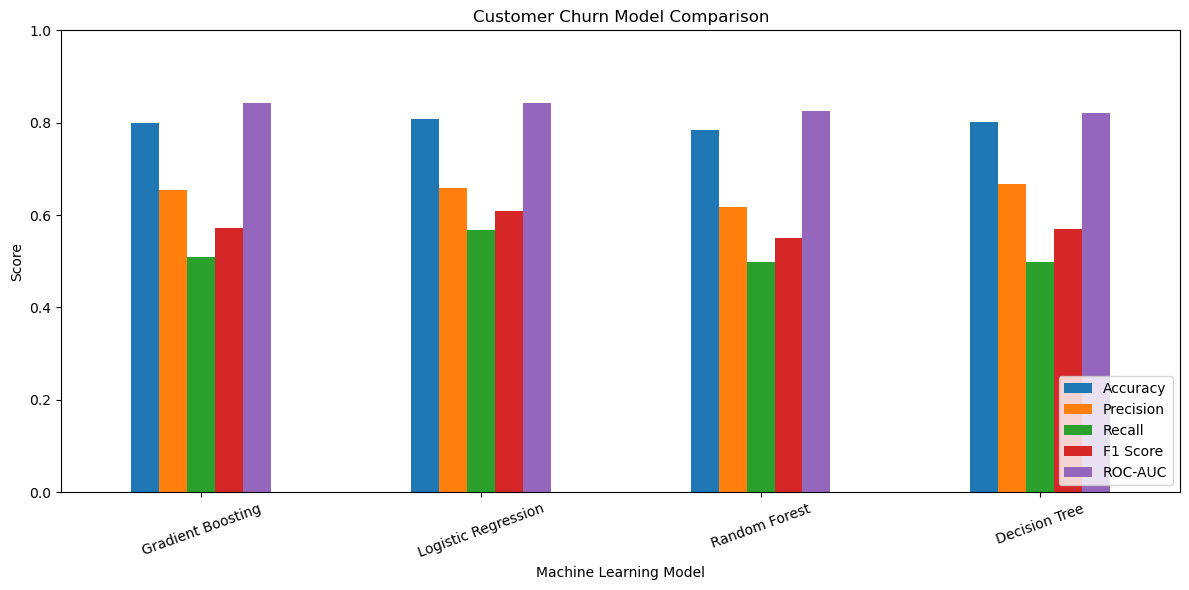

In [15]:
results_df.set_index("Model").plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Customer Churn Model Comparison")
plt.xlabel("Machine Learning Model")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


In [16]:
best_model_name = results_df.loc[
    results_df["ROC-AUC"].idxmax(), "Model"
]

best_model = trained_models[best_model_name]

print("Best-Ranked Model:", best_model_name)

# Generate predictions using the selected model
if best_model_name == "Logistic Regression":
    y_pred = best_model.predict(X_test_scaled)
    y_prob = best_model.predict_proba(X_test_scaled)[:, 1]
else:
    y_pred = best_model.predict(X_test)
    y_prob = best_model.predict_proba(X_test)[:, 1]


Best-Ranked Model: Gradient Boosting


In [17]:
print("Selected Model:", best_model_name)

print("\nClassification Report:")

print(classification_report(
    y_test,
    y_pred,
    target_names=["No Churn", "Churn"],
    zero_division=0
))


Selected Model: Gradient Boosting

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.84      0.90      0.87      1035
       Churn       0.66      0.51      0.57       374

    accuracy                           0.80      1409
   macro avg       0.75      0.71      0.72      1409
weighted avg       0.79      0.80      0.79      1409



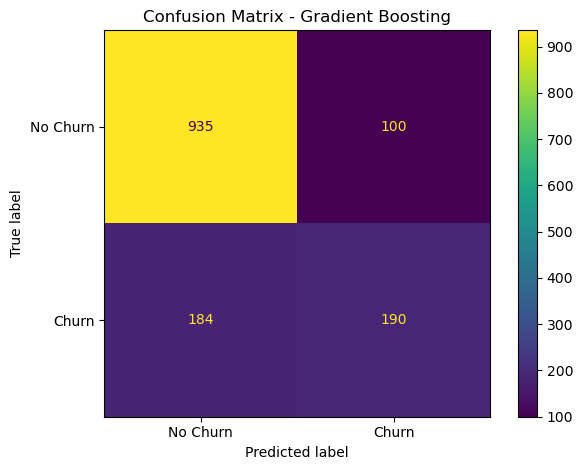

In [18]:
cm = confusion_matrix(y_test, y_pred)

cm_display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Churn", "Churn"]
)

cm_display.plot()
plt.title("Confusion Matrix - " + best_model_name)
plt.tight_layout()
plt.show()

In [19]:
# Save model comparison table
results_df.to_csv(
    "../results/model_comparison.csv",
    index=False
)

In [20]:
## Save actual and predicted churn values

In [23]:
# Create prediction results table

In [24]:
prediction_results = pd.DataFrame({
    "Actual_Churn": y_test,
    "Predicted_Churn": y_pred,
    "Churn_Probability": y_prob
})

In [22]:
prediction_results.to_csv(
    "../results/churn_predictions.csv",
    index=False
)